In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

In [3]:
df = pd.read_csv("/home/patel-krish/anaconda3/BrainyBeam/heart.csv")


Column: age
Q1: 48.0 Q3: 61.0
IQR: 13.0
Lower limit: 28.5
Upper limit: 80.5
IQR outlier count: 0
Mean: 54.43
Standard deviation: 9.07
Z-score outlier count: 0

Column: sex
Q1: 0.0 Q3: 1.0
IQR: 1.0
Lower limit: -1.5
Upper limit: 2.5
IQR outlier count: 0
Mean: 0.7
Standard deviation: 0.46
Z-score outlier count: 0

Column: cp
Q1: 0.0 Q3: 2.0
IQR: 2.0
Lower limit: -3.0
Upper limit: 5.0
IQR outlier count: 0
Mean: 0.94
Standard deviation: 1.03
Z-score outlier count: 0

Column: trestbps
Q1: 120.0 Q3: 140.0
IQR: 20.0
Lower limit: 90.0
Upper limit: 170.0
IQR outlier count: 30
Mean: 131.61
Standard deviation: 17.51
Z-score outlier count: 7

Column: chol
Q1: 211.0 Q3: 275.0
IQR: 64.0
Lower limit: 115.0
Upper limit: 371.0
IQR outlier count: 16
Mean: 246.0
Standard deviation: 51.57
Z-score outlier count: 13

Column: fbs
Q1: 0.0 Q3: 0.0
IQR: 0.0
Lower limit: 0.0
Upper limit: 0.0
IQR outlier count: 153
Mean: 0.15
Standard deviation: 0.36
Z-score outlier count: 0

Column: restecg
Q1: 0.0 Q3: 1.0
IQR:

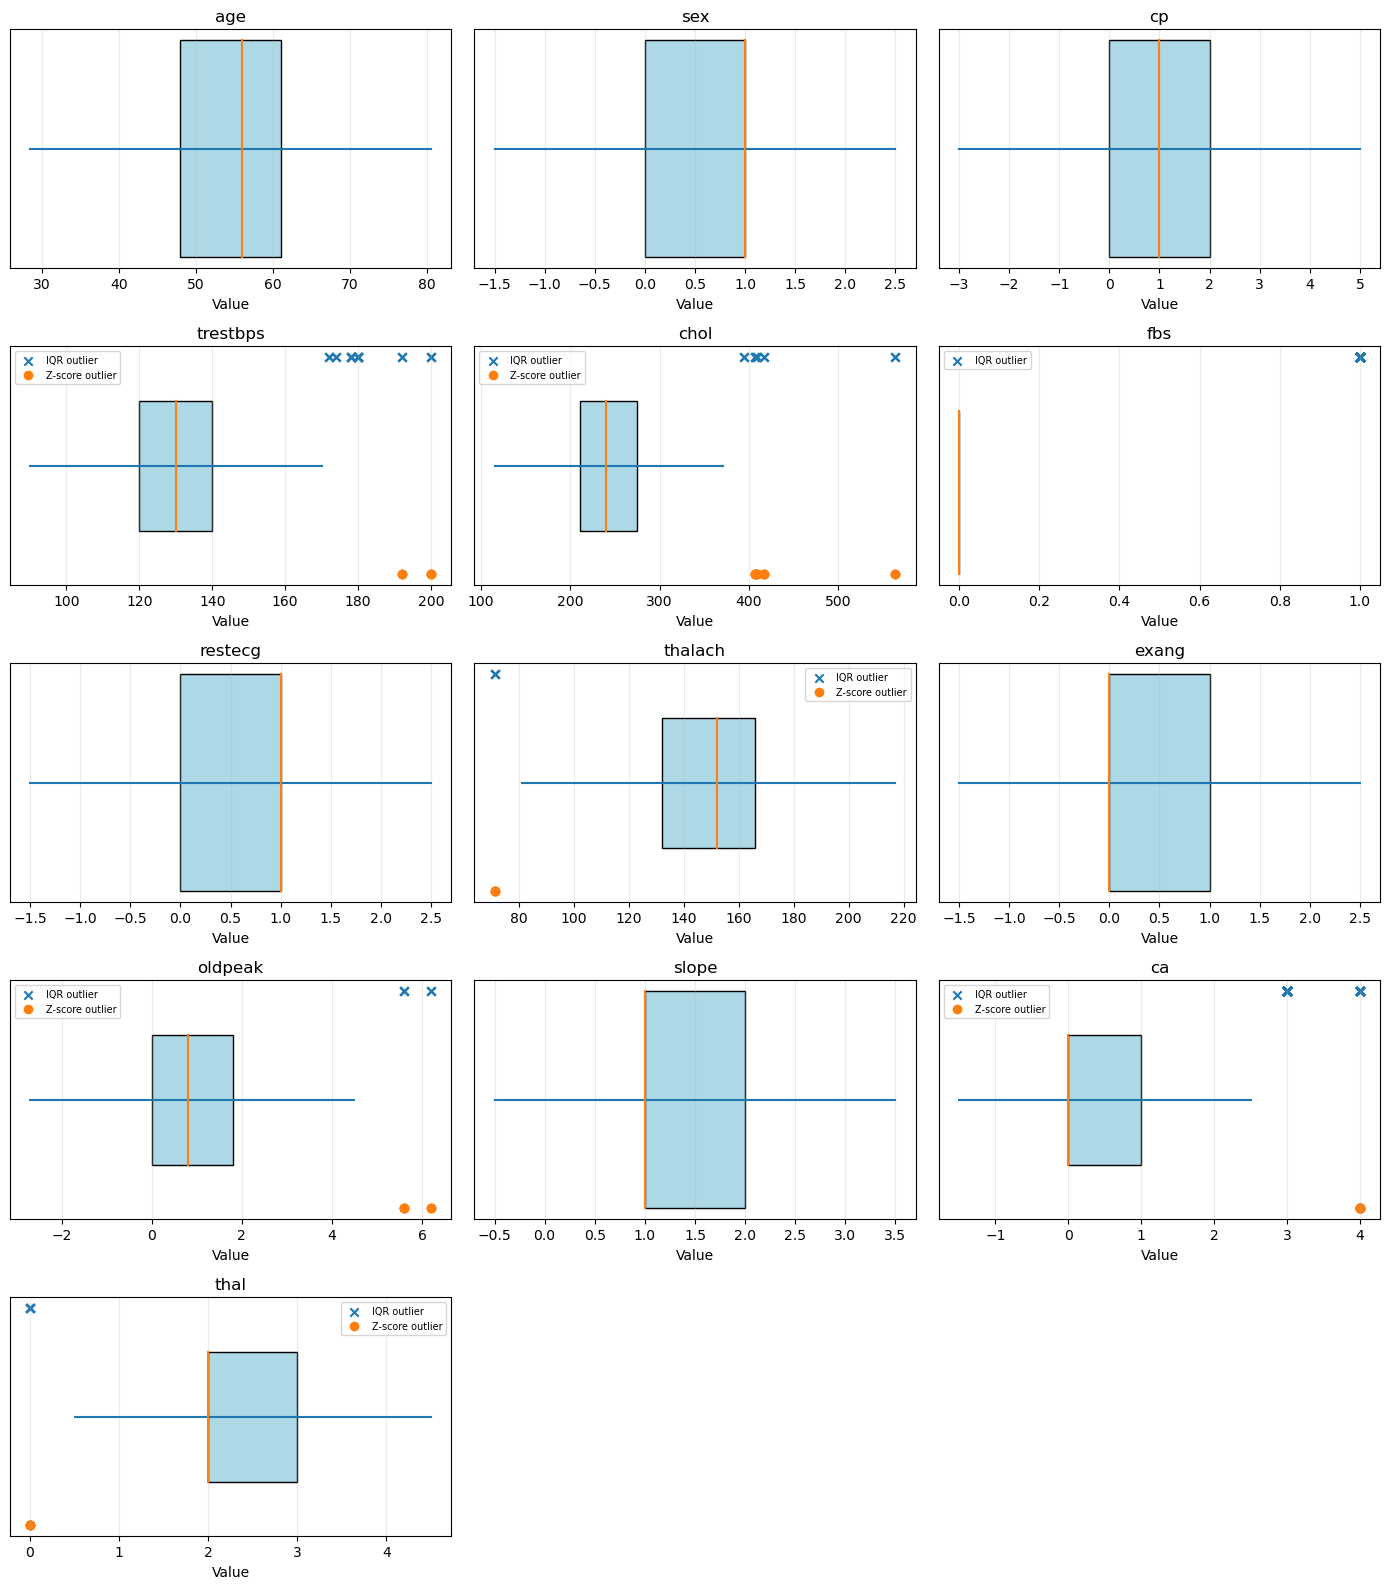

In [4]:
columns = [
    col for col in df.columns
    if col != "target" and pd.api.types.is_numeric_dtype(df[col])
]

def find_median(values):
    values = sorted(values)
    n = len(values)
    mid = n // 2

    if n % 2 == 0:
        return (values[mid - 1] + values[mid]) / 2
    return values[mid]

def find_quartiles(values):
    values = sorted(values)
    n = len(values)

    middle = n // 2
    if n % 2 == 0:
        lower = values[:middle]
        upper = values[middle:]
    else:
        lower = values[:middle]
        upper = values[middle + 1:]

    q1 = find_median(lower)
    median = find_median(values)
    q3 = find_median(upper)

    return q1, median, q3

def find_mean(values):
    total = 0
    for value in values:
        total += value
    return total / len(values)

def find_std(values, mean):
    total = 0
    for value in values:
        total += (value - mean) ** 2
    return (total / len(values)) ** 0.5

results = []

for col in columns:
    values = df[col].dropna().tolist()

    q1, median, q3 = find_quartiles(values)

    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    iqr_outliers = [
        x for x in values if x < lower or x > upper
    ]

    mean = find_mean(values)
    std = find_std(values, mean)

    z_outliers = []
    if std != 0:
        for x in values:
            z = (x - mean) / std
            if abs(z) > 3:
                z_outliers.append(x)

    results.append({
        "column": col,
        "values": values,
        "q1": q1,
        "median": median,
        "q3": q3,
        "lower": lower,
        "upper": upper,
        "iqr_outliers": iqr_outliers,
        "z_outliers": z_outliers
    })

    print("\nColumn:", col)
    print("Q1:", q1, "Q3:", q3)
    print("IQR:", iqr)
    print("Lower limit:", lower)
    print("Upper limit:", upper)
    print("IQR outlier count:", len(iqr_outliers))
    print("Mean:", round(mean, 2))
    print("Standard deviation:", round(std, 2))
    print("Z-score outlier count:", len(z_outliers))

fig, axes = plt.subplots(5, 3, figsize=(14, 16))
axes = axes.flatten()

for ax, result in zip(axes, results):
    q1 = result["q1"]
    q3 = result["q3"]
    median = result["median"]
    lower = result["lower"]
    upper = result["upper"]

    
    ax.plot([lower, upper], [0, 0])

   
    box = Rectangle(
        (q1, -0.15), q3 - q1, 0.30,
        facecolor="lightblue", edgecolor="black"
    )
    ax.add_patch(box)

    
    ax.plot([median, median], [-0.15, 0.15])

    
    outliers = result["iqr_outliers"]
    if outliers:
        ax.scatter(
            outliers, [0.25] * len(outliers),
            marker="x", label="IQR outlier"
        )

 
    outliers = result["z_outliers"]
    if outliers:
        ax.scatter(
            outliers, [-0.25] * len(outliers),
            marker="o", label="Z-score outlier"
        )

    ax.set_title(result["column"])
    ax.set_yticks([])
    ax.set_xlabel("Value")
    ax.grid(axis="x", alpha=0.25)

    if result["iqr_outliers"] or result["z_outliers"]:
        ax.legend(fontsize=7)

for ax in axes[len(results):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()
